# Práctica 2: reducción de dimensionalidad en imágenes de dígitos

**Diplomado en Ciencia de Datos · Aprendizaje no supervisado**

## Objetivo

Representar imágenes de dígitos escritos a mano en menos dimensiones y comparar lo que conservan tres métodos: **PCA**, **MDS** y **t-SNE**. Después, usar las representaciones reducidas para entrenar modelos supervisados que predigan el dígito.

Cada imagen tiene 28 × 28 píxeles. Al convertirla en un vector, cada observación tiene 784 variables y una etiqueta de 0 a 9.

## Actividades y entregables

1. PCA: visualizaciones en 2D y 3D, coloreadas por dígito.
2. MDS: visualizaciones en 2D y 3D, coloreadas por dígito.
3. t-SNE: escoger una dimensión, probar varias configuraciones y guardar las tres mejores visualizaciones con sus parámetros.
4. Modelado: comparar modelos supervisados con datos reducidos. No usar redes neuronales, métodos de ensamble ni kernels no lineales.
5. Guardar las figuras como PNG en la carpeta `salidas`.

> Las imágenes de PCA y MDS se calculan con una muestra para que el notebook pueda ejecutarse en una computadora personal. t-SNE y, en especial, MDS son métodos costosos para conjuntos grandes. La semilla fija hace que las muestras y los resultados sean reproducibles.

## 1. Preparar el ambiente

Usaremos pandas y NumPy para los datos, Matplotlib para las figuras y scikit-learn para las transformaciones y los modelos. Los comentarios indican el propósito de cada paso.

In [29]:
# Importación de herramientas para datos, gráficas y aprendizaje automático
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA
from sklearn.manifold import MDS, TSNE
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# Configuración para que los resultados se puedan repetir
SEMILLA = 42
np.random.seed(SEMILLA)

# Carpeta donde guardaremos las figuras
os.makedirs("salidas", exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

print("Ambiente preparado.")

Ambiente preparado.


## 2. Cargar el conjunto de datos

El conjunto esperado es **MNIST**: 70,000 imágenes de 28 × 28 píxeles, con una etiqueta por imagen.

- Si tienes un CSV local con 785 columnas, este notebook intentará leer `mnist.csv` o `mnist_train.csv`. Debe tener una columna `label`, o la etiqueta debe ser la primera columna y los otros 784 valores los píxeles.
- Si no encuentra un CSV, descargará MNIST desde OpenML. La primera descarga requiere conexión a internet y puede tardar.

Si la profesora proporcionó el dataset con otro nombre o formato, cambia `ARCHIVO_LOCAL` y revisa la estructura de la celda siguiente.

In [30]:
# Si recibiste un CSV con otro nombre, escribe aquí su ruta.
ARCHIVO_LOCAL = None  # Ejemplo: "datos/mnist.csv"

def cargar_mnist(archivo_local=None):
    """Carga MNIST desde un CSV local o, si no existe, desde OpenML."""
    candidatos = [archivo_local] if archivo_local else ["mnist.csv", "mnist_train.csv"]
    ruta = next((ruta for ruta in candidatos if ruta and os.path.exists(ruta)), None)

    if ruta:
        datos = pd.read_csv(ruta)

        # La etiqueta puede llamarse label o estar en la primera columna.
        if "label" in datos.columns:
            etiquetas = datos["label"]
            pixeles = datos.drop(columns=["label"])
        elif datos.shape[1] == 785:
            etiquetas = datos.iloc[:, 0]
            pixeles = datos.iloc[:, 1:]
        else:
            raise ValueError(
                "El CSV debe incluir 784 columnas de pixeles y una columna de etiqueta."
            )

        X = pixeles.to_numpy(dtype=np.float32)
        y = etiquetas.to_numpy(dtype=int)
        print(f"Datos cargados desde: {ruta}")
        return X, y

    print("No se encontró CSV local. Se intentará descargar MNIST desde OpenML...")
    datos = fetch_openml("mnist_784", version=1, as_frame=False, parser="auto")
    X = datos.data.astype(np.float32)
    y = datos.target.astype(int)
    print("Datos cargados desde OpenML.")
    return X, y

X, y = cargar_mnist(ARCHIVO_LOCAL)

print(f"Dimensiones de X: {X.shape}")
print(f"Dimensiones de y: {y.shape}")
print(f"Clases encontradas: {np.unique(y)}")

No se encontró CSV local. Se intentará descargar MNIST desde OpenML...
Datos cargados desde OpenML.
Dimensiones de X: (70000, 784)
Dimensiones de y: (70000,)
Clases encontradas: [0 1 2 3 4 5 6 7 8 9]


### 2.1 Inspeccionar algunas imágenes

Antes de modelar, conviene comprobar que los vectores realmente corresponden a imágenes y que las etiquetas coinciden con lo que vemos.

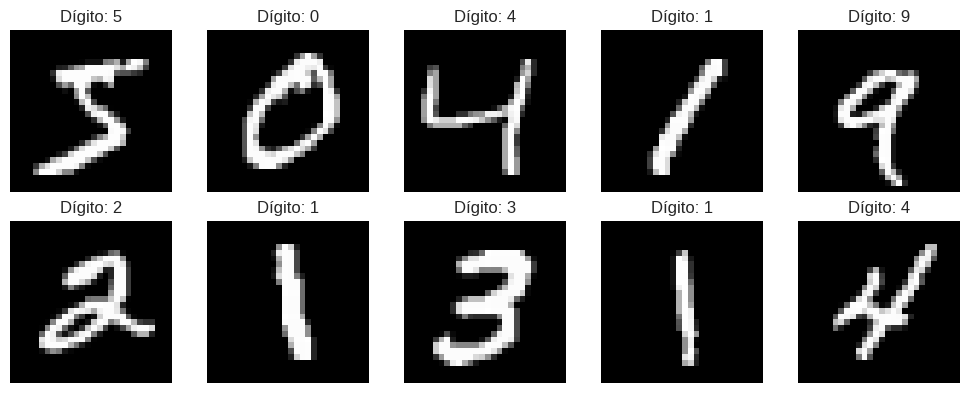

In [31]:
# Mostramos una pequeña selección de imágenes y sus etiquetas
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for indice, ax in enumerate(axes.ravel()):
    ax.imshow(X[indice].reshape(28, 28), cmap="gray")
    ax.set_title(f"Dígito: {y[indice]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### 2.2 Revisar la distribución de etiquetas

Una distribución razonablemente equilibrada ayuda a interpretar las métricas de clasificación. Si hay diferencias entre clases, usaremos particiones estratificadas para conservar sus proporciones.

,cantidad
0,6903
1,7877
2,6990
3,7141
4,6824
5,6313
6,6876
7,7293
8,6825
9,6958


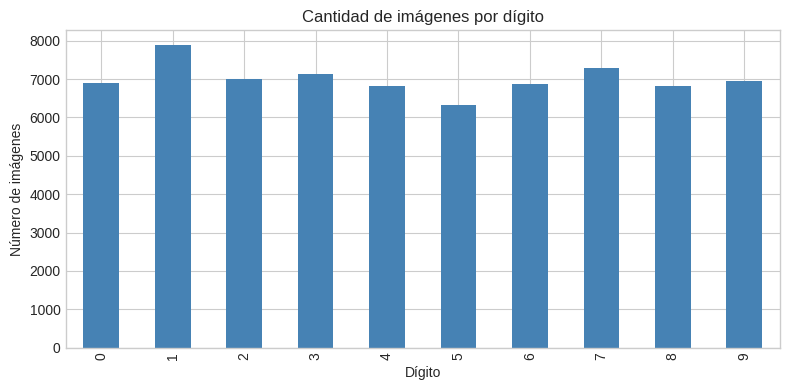

In [32]:
conteo_clases = pd.Series(y).value_counts().sort_index()
display(conteo_clases.to_frame("cantidad"))

conteo_clases.plot(kind="bar", figsize=(8, 4), color="steelblue")
plt.title("Cantidad de imágenes por dígito")
plt.xlabel("Dígito")
plt.ylabel("Número de imágenes")
plt.tight_layout()
plt.show()

## 3. Preparar los datos

Los valores de los píxeles suelen ir de 0 a 255. Los escalamos al rango 0–1 para que todos tengan una escala común. La etiqueta `y` se conserva aparte: sirve para colorear las gráficas y para evaluar los modelos, pero no se usa para calcular PCA, MDS ni t-SNE.

Para que las figuras no sean demasiado pesadas, se seleccionará una muestra aleatoria. La misma muestra se usará para PCA y MDS 2D/3D; t-SNE tendrá un tamaño configurable.

In [33]:
# Normalizamos intensidades de pixeles al rango 0-1
X = X / 255.0

# Creamos una muestra reproducible para PCA y MDS
MAX_VISUALIZACIONES = min(3000, len(X))
rng = np.random.default_rng(SEMILLA)
indices_visualizacion = rng.choice(len(X), size=MAX_VISUALIZACIONES, replace=False)

X_visual = X[indices_visualizacion]
y_visual = y[indices_visualizacion]

print(f"Observaciones para PCA y MDS: {len(X_visual)}")
print(f"Variables de entrada por imagen: {X_visual.shape[1]}")

Observaciones para PCA y MDS: 3000
Variables de entrada por imagen: 784


## 4. PCA: Componentes Principales

PCA es un método lineal que busca direcciones que expliquen la mayor variación posible de los datos. Reduciremos las 784 variables a dos y a tres componentes. La etiqueta se agrega después de transformar, únicamente para colorear los puntos.

In [34]:
# PCA en 2 dimensiones
pca_2d = PCA(n_components=2, random_state=SEMILLA)
X_pca_2d = pca_2d.fit_transform(X_visual)

print(
    "Varianza explicada por PC1 y PC2: "
    f"{pca_2d.explained_variance_ratio_.sum() * 100:.2f}%"
)

Varianza explicada por PC1 y PC2: 17.22%


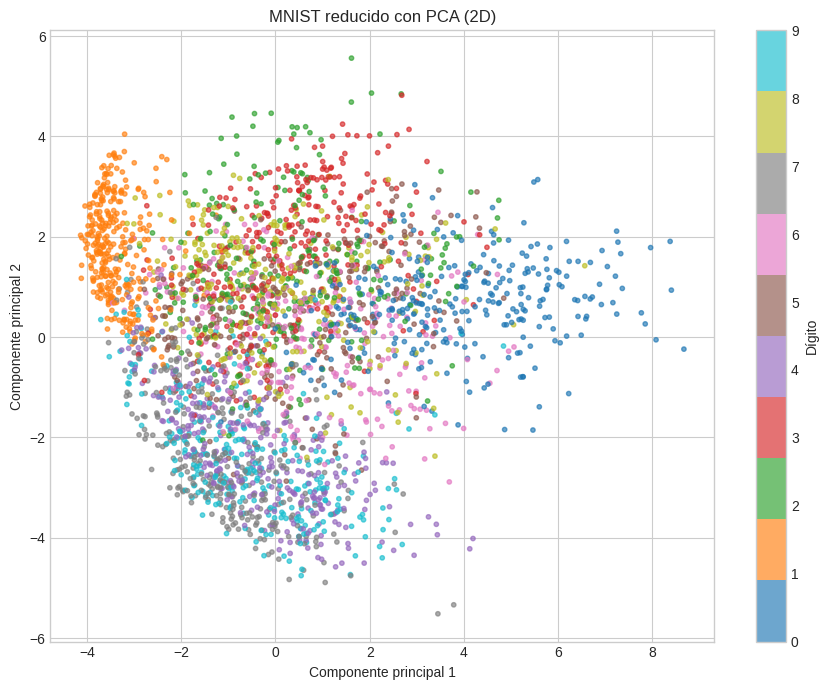

In [35]:
# Gráfica PCA 2D
fig, ax = plt.subplots(figsize=(9, 7))
puntos = ax.scatter(
    X_pca_2d[:, 0], X_pca_2d[:, 1],
    c=y_visual, cmap="tab10", s=10, alpha=0.65
)
ax.set_title("MNIST reducido con PCA (2D)")
ax.set_xlabel("Componente principal 1")
ax.set_ylabel("Componente principal 2")
fig.colorbar(puntos, ax=ax, ticks=range(10), label="Dígito")
plt.tight_layout()
plt.savefig("salidas/pca_2d.png", dpi=160, bbox_inches="tight")
plt.show()

In [36]:
# PCA en 3 dimensiones
pca_3d = PCA(n_components=3, random_state=SEMILLA)
X_pca_3d = pca_3d.fit_transform(X_visual)

print(
    "Varianza explicada por PC1, PC2 y PC3: "
    f"{pca_3d.explained_variance_ratio_.sum() * 100:.2f}%"
)

Varianza explicada por PC1, PC2 y PC3: 23.09%


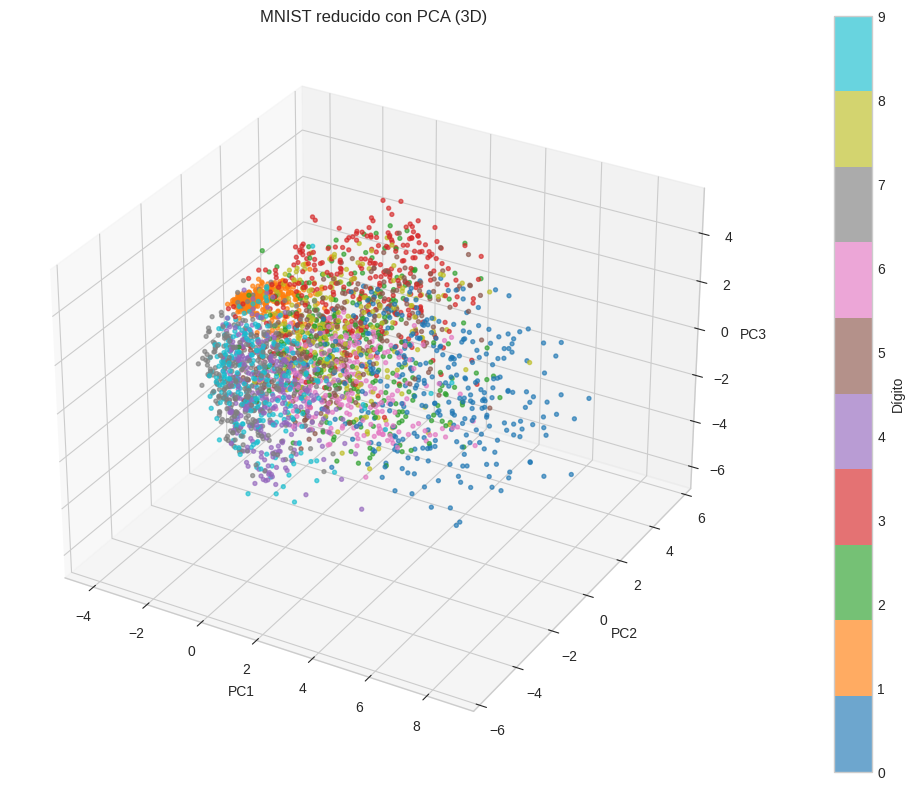

In [37]:
# Gráfica PCA 3D
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")
puntos = ax.scatter(
    X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2],
    c=y_visual, cmap="tab10", s=8, alpha=0.65
)
ax.set_title("MNIST reducido con PCA (3D)")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
fig.colorbar(puntos, ax=ax, ticks=range(10), label="Dígito", pad=0.1)
plt.tight_layout()
plt.savefig("salidas/pca_3d.png", dpi=160, bbox_inches="tight")
plt.show()

Las figuras se guardan en `salidas/pca_2d.png` y `salidas/pca_3d.png`. Observa si algunos dígitos aparecen más separados y recuerda que PCA prioriza la varianza total, no la clasificación por etiqueta.

## 5. MDS: Escalamiento Multidimensional

MDS intenta conservar las distancias entre observaciones. Calcular todas las distancias para miles de imágenes consume mucha memoria y tiempo, por lo que reducimos aún más la muestra. Para la práctica puedes ajustar `MAX_MDS`: un valor menor termina antes; uno mayor representa más observaciones, pero puede tardar mucho.

In [38]:
# MDS trabaja con pares de observaciones, así que usamos una muestra moderada
MAX_MDS = min(800, len(X_visual))
indices_mds = rng.choice(len(X_visual), size=MAX_MDS, replace=False)
X_mds_entrada = X_visual[indices_mds]
y_mds = y_visual[indices_mds]

print(f"Observaciones para MDS: {len(X_mds_entrada)}")

Observaciones para MDS: 800


In [39]:
# MDS en 2 dimensiones
mds_2d = MDS(
    n_components=2,
    random_state=SEMILLA,
    n_init=1,
    max_iter=100,
    normalized_stress="auto"
)
X_mds_2d = mds_2d.fit_transform(X_mds_entrada)

print(f"Stress de MDS 2D: {mds_2d.stress_:.2f}")

Stress de MDS 2D: 5108405.05


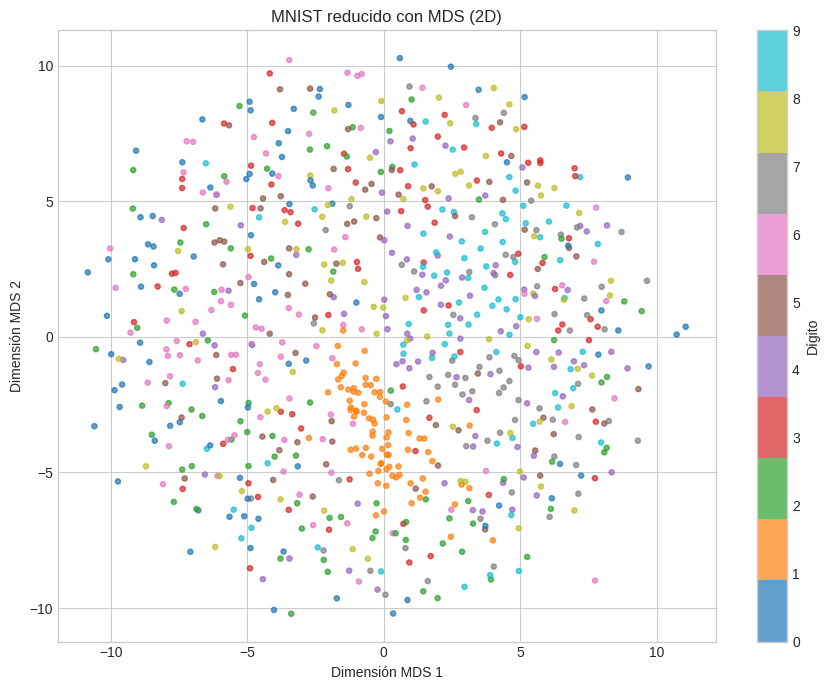

In [40]:
# Gráfica MDS 2D
fig, ax = plt.subplots(figsize=(9, 7))
puntos = ax.scatter(
    X_mds_2d[:, 0], X_mds_2d[:, 1],
    c=y_mds, cmap="tab10", s=14, alpha=0.7
)
ax.set_title("MNIST reducido con MDS (2D)")
ax.set_xlabel("Dimensión MDS 1")
ax.set_ylabel("Dimensión MDS 2")
fig.colorbar(puntos, ax=ax, ticks=range(10), label="Dígito")
plt.tight_layout()
plt.savefig("salidas/mds_2d.png", dpi=160, bbox_inches="tight")
plt.show()

In [41]:
# MDS en 3 dimensiones
mds_3d = MDS(
    n_components=3,
    random_state=SEMILLA,
    n_init=1,
    max_iter=100,
    normalized_stress="auto"
)
X_mds_3d = mds_3d.fit_transform(X_mds_entrada)

print(f"Stress de MDS 3D: {mds_3d.stress_:.2f}")

Stress de MDS 3D: 3134875.04


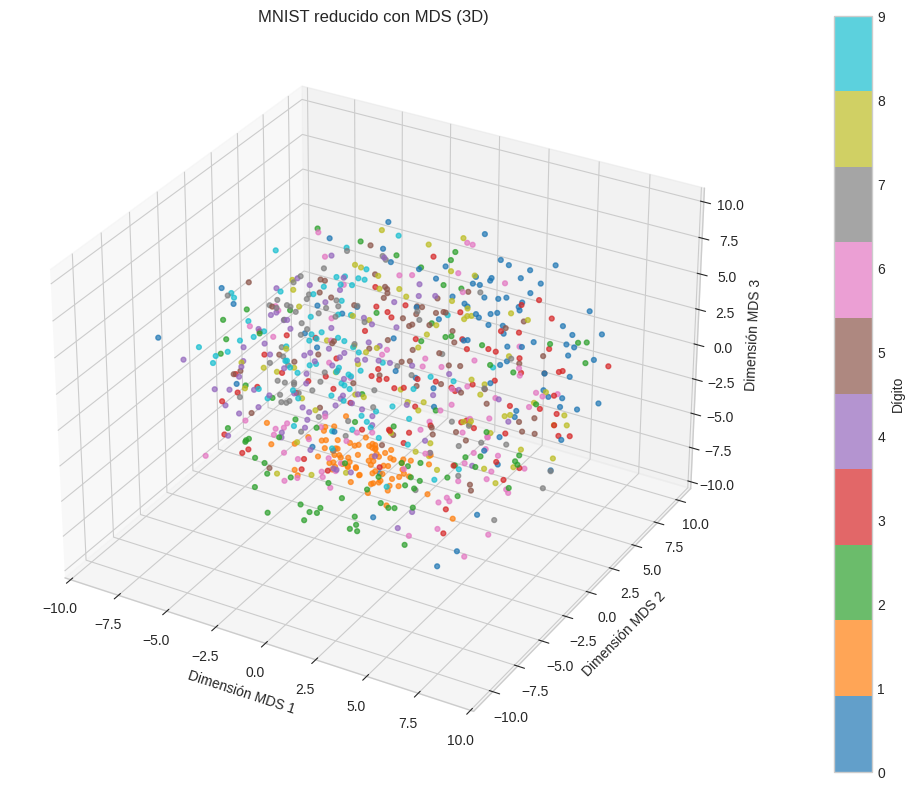

In [42]:
# Gráfica MDS 3D
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")
puntos = ax.scatter(
    X_mds_3d[:, 0], X_mds_3d[:, 1], X_mds_3d[:, 2],
    c=y_mds, cmap="tab10", s=12, alpha=0.7
)
ax.set_title("MNIST reducido con MDS (3D)")
ax.set_xlabel("Dimensión MDS 1")
ax.set_ylabel("Dimensión MDS 2")
ax.set_zlabel("Dimensión MDS 3")
fig.colorbar(puntos, ax=ax, ticks=range(10), label="Dígito", pad=0.1)
plt.tight_layout()
plt.savefig("salidas/mds_3d.png", dpi=160, bbox_inches="tight")
plt.show()

MDS puede tardar varios minutos, especialmente en 3D. Las gráficas se guardan como `salidas/mds_2d.png` y `salidas/mds_3d.png`. Un stress menor indica que el mapa reducido conserva mejor las distancias de la muestra, aunque los valores no deben compararse como si fueran una métrica de clasificación.

## 6. t-SNE: probar configuraciones

Elegimos **2 dimensiones** para facilitar la lectura y la entrega de las gráficas. t-SNE intenta conservar vecindarios locales; por eso sus ejes no tienen una interpretación directa y las distancias entre grupos lejanos no siempre son comparables.

La perplejidad influye en el tamaño efectivo del vecindario. Probaremos tres configuraciones y guardaremos cada resultado junto con sus parámetros. Para acelerar el cálculo, primero proyectaremos a 30 componentes PCA, práctica común para imágenes de alta dimensión.

Ajusta `MAX_TSNE` y los parámetros si tu computadora tarda demasiado. La perplejidad debe ser menor que el número de observaciones.

In [43]:
# Preparamos una muestra fija para comparar configuraciones t-SNE
MAX_TSNE = min(3000, len(X))
indices_tsne = rng.choice(len(X), size=MAX_TSNE, replace=False)
X_tsne_original = X[indices_tsne]
y_tsne = y[indices_tsne]

# PCA previo reduce ruido y acelera t-SNE
pca_previo = PCA(n_components=30, random_state=SEMILLA)
X_tsne_entrada = pca_previo.fit_transform(X_tsne_original)

print(f"Observaciones para t-SNE: {len(X_tsne_entrada)}")
print(f"Varianza explicada por los 30 componentes: "
      f"{pca_previo.explained_variance_ratio_.sum() * 100:.2f}%")

Observaciones para t-SNE: 3000
Varianza explicada por los 30 componentes: 73.54%


In [44]:
# Tres combinaciones para comparar
configuraciones_tsne = [
    {"perplexity": 20, "learning_rate": "auto", "init": "pca"},
    {"perplexity": 30, "learning_rate": "auto", "init": "pca"},
    {"perplexity": 50, "learning_rate": 200, "init": "pca"}
]

resultados_tsne = []

for numero, parametros in enumerate(configuraciones_tsne, start=1):
    print(f"Calculando configuración {numero}: {parametros}")

    modelo_tsne = TSNE(
        n_components=2,
        perplexity=parametros["perplexity"],
        learning_rate=parametros["learning_rate"],
        init=parametros["init"],
        random_state=SEMILLA,
        max_iter=1000
    )
    coordenadas = modelo_tsne.fit_transform(X_tsne_entrada)

    resultados_tsne.append({
        "configuracion": numero,
        "parametros": parametros,
        "coordenadas": coordenadas,
        "kl_divergence": modelo_tsne.kl_divergence_
    })

print("Terminó el cálculo de las configuraciones.")

Calculando configuración 1: {'perplexity': 20, 'learning_rate': 'auto', 'init': 'pca'}
Calculando configuración 2: {'perplexity': 30, 'learning_rate': 'auto', 'init': 'pca'}
Calculando configuración 3: {'perplexity': 50, 'learning_rate': 200, 'init': 'pca'}
Terminó el cálculo de las configuraciones.


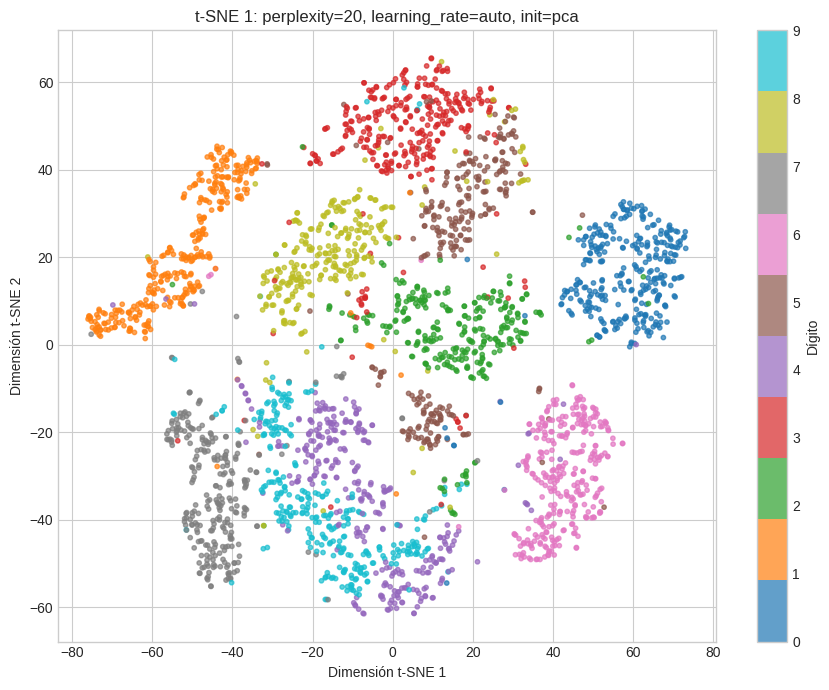

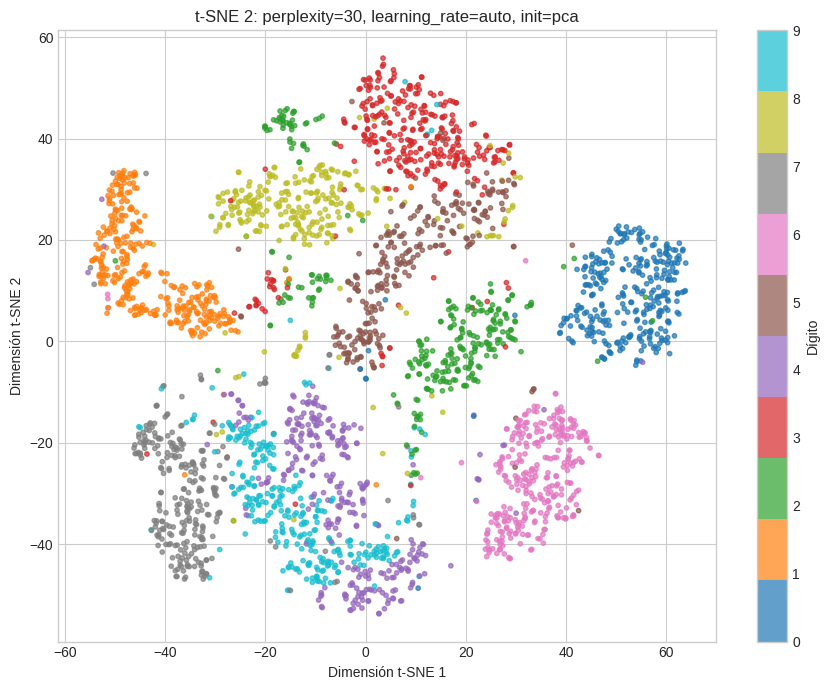

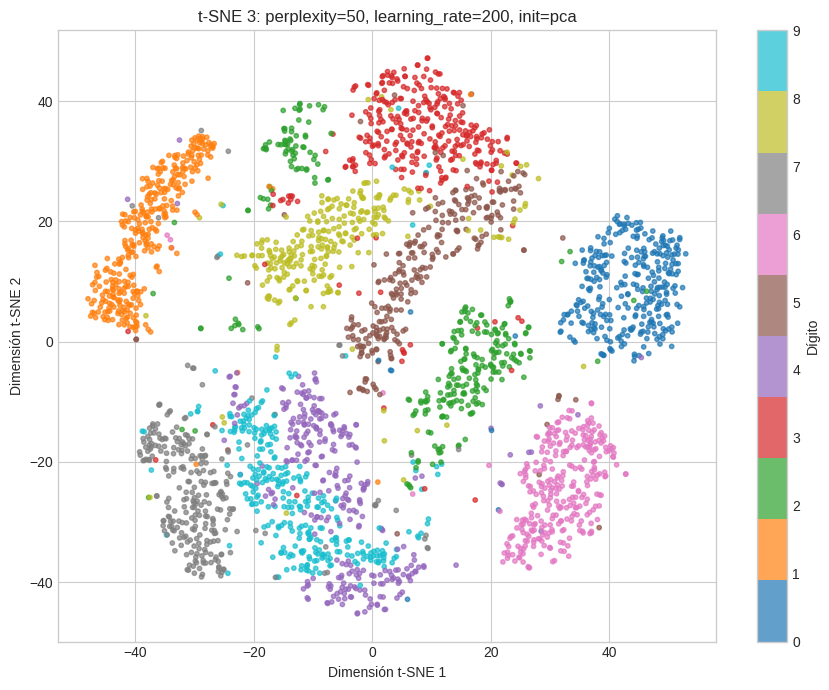

In [45]:
# Graficamos y guardamos cada configuración para compararlas
for resultado in resultados_tsne:
    parametros = resultado["parametros"]
    coordenadas = resultado["coordenadas"]
    numero = resultado["configuracion"]

    fig, ax = plt.subplots(figsize=(9, 7))
    puntos = ax.scatter(
        coordenadas[:, 0], coordenadas[:, 1],
        c=y_tsne, cmap="tab10", s=10, alpha=0.7
    )
    ax.set_title(
        f"t-SNE {numero}: perplexity={parametros['perplexity']}, "
        f"learning_rate={parametros['learning_rate']}, init={parametros['init']}"
    )
    ax.set_xlabel("Dimensión t-SNE 1")
    ax.set_ylabel("Dimensión t-SNE 2")
    fig.colorbar(puntos, ax=ax, ticks=range(10), label="Dígito")
    plt.tight_layout()
    plt.savefig(f"salidas/tsne_configuracion_{numero}.png",
                dpi=160, bbox_inches="tight")
    plt.show()

In [46]:
# Tabla de parámetros y divergencia KL (valor de ajuste interno de t-SNE)
tabla_tsne = pd.DataFrame([
    {
        "configuracion": r["configuracion"],
        **r["parametros"],
        "divergencia_KL": r["kl_divergence"]
    }
    for r in resultados_tsne
]).sort_values("divergencia_KL")

display(tabla_tsne)

,configuracion,perplexity,learning_rate,init,divergencia_KL
2,3,50,200,pca,1.246580
1,2,30,auto,pca,1.333215
0,1,20,auto,pca,1.372091


La divergencia KL ayuda a describir el ajuste de t-SNE para una configuración, pero no basta por sí sola para elegir la “mejor” figura. Compara visualmente qué configuraciones separan los dígitos con mayor claridad y registra esa elección en las conclusiones. Las tres figuras quedan en `salidas/tsne_configuracion_1.png`, `..._2.png` y `..._3.png`.

## 7. Modelado supervisado con datos reducidos

Para estimar las etiquetas, reduciremos los píxeles mediante PCA y compararemos **Regresión Logística** y **K vecinos más cercanos (KNN)**. Ambos son modelos supervisados clásicos y cumplen las restricciones de la práctica.

No usaremos las coordenadas t-SNE como entrada de clasificación: t-SNE de scikit-learn no ofrece una transformación directa para observaciones nuevas. Además, ajustar t-SNE con todos los datos antes de separar entrenamiento y prueba filtraría información de la prueba. En cambio, PCA se ajusta dentro de cada pipeline usando solamente los datos de entrenamiento.

Para reducir el tiempo de búsqueda, el ajuste de hiperparámetros usa una submuestra estratificada del conjunto de entrenamiento; después se evaluará el mejor modelo en un conjunto de prueba que no participó en el ajuste.

In [47]:
# Separamos entrenamiento y prueba antes de ajustar cualquier transformación
X_entrena, X_prueba, y_entrena, y_prueba = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEMILLA,
    stratify=y
)

print(f"Entrenamiento: {X_entrena.shape}")
print(f"Prueba: {X_prueba.shape}")

Entrenamiento: (56000, 784)
Prueba: (14000, 784)


In [48]:
# Submuestra estratificada para que GridSearchCV sea manejable
TAMANO_BUSQUEDA = min(12000, len(X_entrena))
X_busqueda, _, y_busqueda, _ = train_test_split(
    X_entrena,
    y_entrena,
    train_size=TAMANO_BUSQUEDA,
    random_state=SEMILLA,
    stratify=y_entrena
)

print(f"Observaciones usadas para buscar hiperparámetros: {len(X_busqueda)}")

Observaciones usadas para buscar hiperparámetros: 12000


In [49]:
# Cada pipeline aprende PCA dentro de cada partición de validación
# Así evitamos ajustar PCA con información que pertenece a validación/prueba.
pipeline_logistica = Pipeline([
    ("escalador", StandardScaler()),
    ("pca", PCA(n_components=50, random_state=SEMILLA)),
    ("modelo", LogisticRegression(max_iter=1000, solver="lbfgs"))
])

pipeline_knn = Pipeline([
    ("escalador", StandardScaler()),
    ("pca", PCA(n_components=50, random_state=SEMILLA)),
    ("modelo", KNeighborsClassifier())
])

parametros_logistica = {
    "modelo__C": [0.1, 1, 10]
}

parametros_knn = {
    "modelo__n_neighbors": [3, 5, 7],
    "modelo__weights": ["uniform", "distance"]
}

busqueda_logistica = GridSearchCV(
    pipeline_logistica,
    parametros_logistica,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

busqueda_knn = GridSearchCV(
    pipeline_knn,
    parametros_knn,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

busqueda_logistica.fit(X_busqueda, y_busqueda)
busqueda_knn.fit(X_busqueda, y_busqueda)

print("Mejores parámetros de Regresión Logística:", busqueda_logistica.best_params_)
print("Mejor accuracy de validación:", round(busqueda_logistica.best_score_, 4))
print()
print("Mejores parámetros de KNN:", busqueda_knn.best_params_)
print("Mejor accuracy de validación:", round(busqueda_knn.best_score_, 4))

Mejores parámetros de Regresión Logística: {'modelo__C': 0.1}
Mejor accuracy de validación: 0.8958

Mejores parámetros de KNN: {'modelo__n_neighbors': 5, 'modelo__weights': 'distance'}
Mejor accuracy de validación: 0.9299


In [50]:
# Evaluamos los mejores modelos en el conjunto de prueba
modelos = {
    "Regresión Logística": busqueda_logistica.best_estimator_,
    "KNN": busqueda_knn.best_estimator_
}

resultados_modelos = []

for nombre, modelo in modelos.items():
    predicciones = modelo.predict(X_prueba)
    exactitud = accuracy_score(y_prueba, predicciones)

    resultados_modelos.append({
        "modelo": nombre,
        "accuracy_prueba": exactitud
    })

    print(f"=== {nombre} ===")
    print(f"Accuracy en prueba: {exactitud:.4f}")
    print(classification_report(y_prueba, predicciones, digits=3))

tabla_modelos = pd.DataFrame(resultados_modelos).sort_values(
    "accuracy_prueba", ascending=False
)
display(tabla_modelos)

=== Regresión Logística ===
Accuracy en prueba: 0.8974
              precision    recall  f1-score   support

           0      0.934     0.960     0.947      1381
           1      0.935     0.966     0.950      1575
           2      0.901     0.866     0.883      1398
           3      0.869     0.870     0.869      1428
           4      0.899     0.904     0.902      1365
           5      0.852     0.836     0.844      1263
           6      0.927     0.943     0.935      1375
           7      0.915     0.918     0.917      1459
           8      0.866     0.830     0.847      1365
           9      0.862     0.866     0.864      1391

    accuracy                          0.897     14000
   macro avg      0.896     0.896     0.896     14000
weighted avg      0.897     0.897     0.897     14000

=== KNN ===
Accuracy en prueba: 0.9376
              precision    recall  f1-score   support

           0      0.962     0.986     0.974      1381
           1      0.959     0.987     

,modelo,accuracy_prueba
1,KNN,0.937643
0,Regresión Logística,0.897429


### 7.1 Elegir el mejor resultado

Compara el accuracy de prueba y el reporte por clase. La clase de mayor accuracy no siempre es el modelo más útil: revisa también precision, recall y F1-score para cada dígito. Como la prueba se separó antes del ajuste, estas métricas ofrecen una evaluación más honesta del desempeño esperado.

In [51]:
# Identificamos el modelo con mayor accuracy de prueba
mejor_nombre = tabla_modelos.iloc[0]["modelo"]
mejor_accuracy = tabla_modelos.iloc[0]["accuracy_prueba"]

print(f"Mejor modelo: {mejor_nombre}")
print(f"Accuracy en prueba: {mejor_accuracy:.4f}")
print("Parámetros:")
print(modelos[mejor_nombre].get_params())

Mejor modelo: KNN
Accuracy en prueba: 0.9376
Parámetros:
{'memory': None, 'steps': [('escalador', StandardScaler()), ('pca', PCA(n_components=50, random_state=42)), ('modelo', KNeighborsClassifier(weights='distance'))], 'transform_input': None, 'verbose': False, 'escalador': StandardScaler(), 'pca': PCA(n_components=50, random_state=42), 'modelo': KNeighborsClassifier(weights='distance'), 'escalador__copy': True, 'escalador__with_mean': True, 'escalador__with_std': True, 'pca__copy': True, 'pca__iterated_power': 'auto', 'pca__n_components': 50, 'pca__n_oversamples': 10, 'pca__power_iteration_normalizer': 'auto', 'pca__random_state': 42, 'pca__svd_solver': 'auto', 'pca__tol': 0.0, 'pca__whiten': False, 'modelo__algorithm': 'auto', 'modelo__leaf_size': 30, 'modelo__metric': 'minkowski', 'modelo__metric_params': None, 'modelo__n_jobs': None, 'modelo__n_neighbors': 5, 'modelo__p': 2, 'modelo__weights': 'distance'}


## 8. Conclusiones

**1. ¿Qué tan separados quedaron los dígitos con PCA en 2D y en 3D? ¿Qué porcentaje de varianza explicaron sus componentes?**

En 2D el 1 queda aislado a la izquierda y el 0 se extiende a la derecha; el 4, el 7 y el 9 se encuentran en la parte inferior y los dígitos 2, 3, 5 y 8 se mezclan al centro. En 3D sigue habiendo una sola nube con los mismos extremos; la tercera componente parece separar algo el 3, pero el traslape se mantiene. Las 2 primeras componentes explican 17.22% de la varianza y las 3 primeras 23.09%, es decir, se pierde la mayor parte de la información, y por eso hay tanto traslape.

**2. ¿Cómo cambió la representación de MDS entre 2D y 3D? ¿Qué indica su stress?**

En ambos casos solo el 1 forma un grupo reconocible; el resto de los dígitos se mezcla en una nube casi uniforme (un disco en 2D y una nube redondeada en 3D). El stress bajó de 5,108,405 en 2D a 3,134,875 en 3D (38.6% menos): con una dimensión más hay más espacio para respetar las distancias originales, así que se conservan mejor. Sirve para comparar ambas dimensiones con la misma muestra (800 imágenes), no como valor absoluto.

**3. ¿Qué configuración de t-SNE distinguió mejor las clases? Escribe los parámetros y describe la diferencia visual.**

La configuración 1: `perplexity=20`, `learning_rate="auto"`, `init="pca"`. A simple vista, el 0, el 1, el 3 y el 6 quedan en grupos compactos y bien separados, el 2 se mantiene casi en un solo grupo y hay más espacio vacío entre los grupos. En las configuraciones 2 (`perplexity=30`) y 3 (`perplexity=50`, `learning_rate=200`) aparecen fragmentos del 2 separados de su grupo principal y el 5 se estira en una franja diagonal. En las tres, el 4 y el 9 siguen mezclados. La divergencia KL fue menor en la configuración 3 (1.2466) que en la 1 (1.3721), pero no se usó para elegir porque no es comparable entre perplexities distintas; las diferencias visuales entre las tres son moderadas.

**4. ¿Qué modelo supervisado obtuvo el mejor resultado en el conjunto de prueba? Incluye sus hiperparámetros y métricas.**

KNN, con un pipeline de `StandardScaler`, PCA a 50 componentes y `KNeighborsClassifier(n_neighbors=5, weights="distance")`. Obtuvo exactitud de 0.9376 en prueba (validación cruzada: 0.9299) y F1 macro de 0.937. La regresión logística (`C=0.1`) obtuvo 0.8974 y F1 macro de 0.896, así que KNN quedó 4.0 puntos porcentuales arriba. KNN fue mejor en los 10 dígitos; sus mejores F1 son el 0 (0.974) y el 1 (0.972) y el más difícil es el 9 (0.889).

**5. ¿Qué limitaciones observaste en el tiempo de ejecución y en las representaciones reducidas?**

*Tiempo:* MDS y t-SNE crecen con el cuadrado del número de imágenes, por eso se usaron 800 y 3,000 imágenes de las 70,000, y MDS se limitó a 100 iteraciones sin verificar si convergió. La búsqueda de hiperparámetros usó 12,000 de las 56,000 imágenes de entrenamiento. *Representaciones:* con 2 y 3 componentes PCA conserva solo 17.22% y 23.09% de la varianza; t-SNE separa mejor, pero sus ejes y las distancias entre grupos no se pueden interpretar y no sirve para proyectar imágenes nuevas; ninguna técnica separó el 4 del 9. Además, solo se probaron tres configuraciones de t-SNE y la elección fue visual.

## 9. Archivos generados

Al ejecutar el notebook se crean estas figuras PNG en `salidas`:

- `pca_2d.png` y `pca_3d.png`
- `mds_2d.png` y `mds_3d.png`
- `tsne_configuracion_1.png`, `tsne_configuracion_2.png` y `tsne_configuracion_3.png`

Revisa que las imágenes se vean correctamente antes de entregarlas y adjunta la tabla de resultados de modelado con la configuración ganadora.